<a href="https://colab.research.google.com/github/L1ght6/MN_HORA_4_9/blob/main/%D0%9B%D0%A04_%D0%93%D0%BE%D1%80%D0%B0_%D0%A4%D0%86%D0%A24_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


Гора Р.В ФІТ4-9

https://colab.research.google.com/drive/1ow0CgUEfQw8v4miyPAQyL7RV83hUeqmY?usp=sharing

---

https://github.com/L1ght6/MN_HORA_4_9/blob/main/%D0%9B%D0%A04_%D0%93%D0%BE%D1%80%D0%B0_%D0%A4%D0%86%D0%A24_9.ipynb

## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import pandas as pd

df = pd.read_csv('CarPrice_Assignment.csv')

print("Кількість об'єктів і ознак:", df.shape)

print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nТипи даних:")
print(df.dtypes)

target_variable = 'price'
print(f"\nЦільова змінна: {target_variable}")

print("\nОсновні статистичні характеристики:")
display(df.describe())

Кількість об'єктів і ознак: (205, 26)

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [2]:
print("Пропущені значення:")
print(df.isnull().sum())

print("\nПовні дублікати (без car_ID):")
print(df.drop(columns=['car_ID']).duplicated().sum())

print("\nКількість унікальних значень:")
print(df.nunique())

Пропущені значення:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Повні дублікати (без car_ID):
0

Кількість унікальних значень:
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight         

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [3]:
car_ids = df['car_ID']
df_features = df.drop(columns=['car_ID'])

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


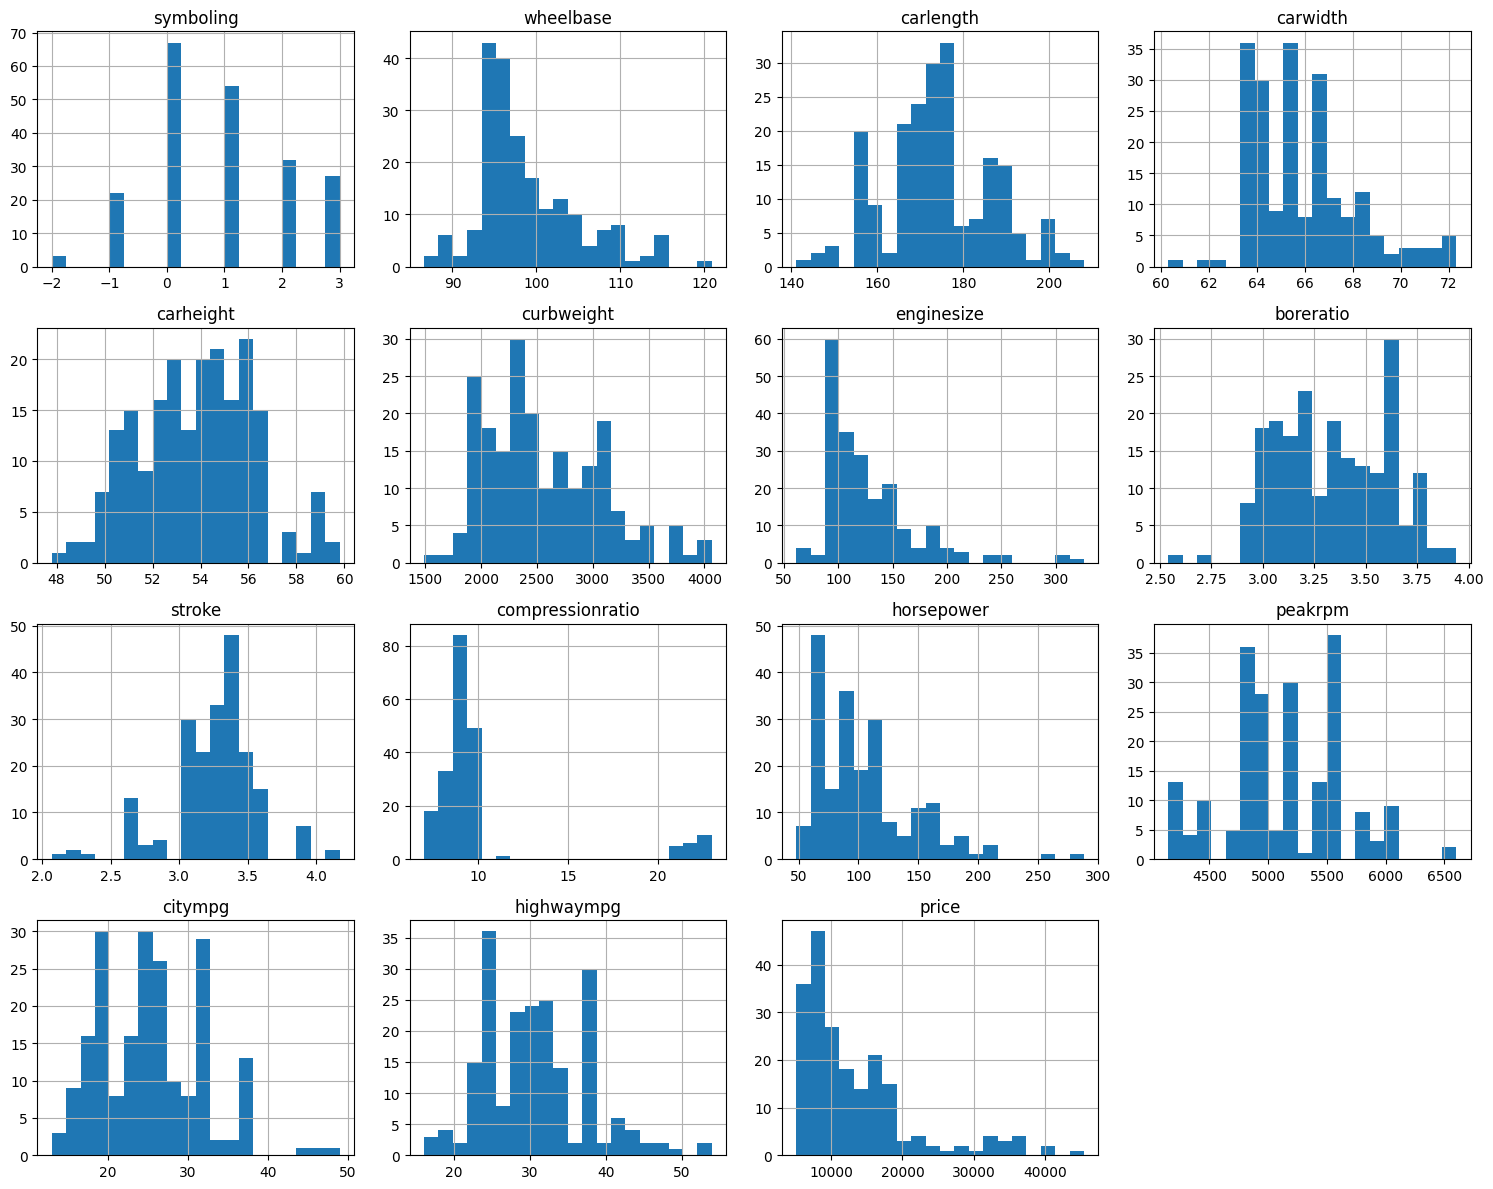

Коефіцієнти асиметрії:
 compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з найбільш вираженою асиметрією:
 compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df_features.select_dtypes(include=['number']).columns

df_features[num_cols].hist(bins=20, figsize=(15, 12))
plt.tight_layout()
plt.show()

skewness = df_features[num_cols].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії:\n", skewness)

highly_skewed = skewness[abs(skewness) > 1]
print("\nОзнаки з найбільш вираженою асиметрією:\n", highly_skewed)


Низка числових ознак (зокрема, об'єм двигуна, ціна) мають значну правосторонню асиметрію. Це вказує на наявність екстремально високих значень та потребує застосування трансформацій для наближення розподілів до нормального.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [6]:
from sklearn.model_selection import train_test_split

X = df_features.drop(columns=['price'])
y = df_features['price']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [7]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')

continuous_cols = X_train.select_dtypes(include=['number']).columns.drop('symboling', errors='ignore')

bounds = {}
print("Кількість потенційних викидів:")
for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    bounds[col] = (lower_bound, upper_bound)

    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    print(f"{col}: {outliers_count}")

for col in continuous_cols:
    lower, upper = bounds[col]
    X_train.loc[:, col] = np.clip(X_train[col], lower, upper)
    X_test.loc[:, col] = np.clip(X_test[col], lower, upper)


Кількість потенційних викидів:
wheelbase: 6
carlength: 0
carwidth: 10
carheight: 0
curbweight: 0
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
citympg: 0
highwaympg: 1


Оскільки датасет невеликий, видалення рядків призвело б до втрати цінної інформації. Тому було обрано метод кліпінгу (обмеження крайніх значень) за межами IQR, обчисленими виключно на тренувальній вибірці.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


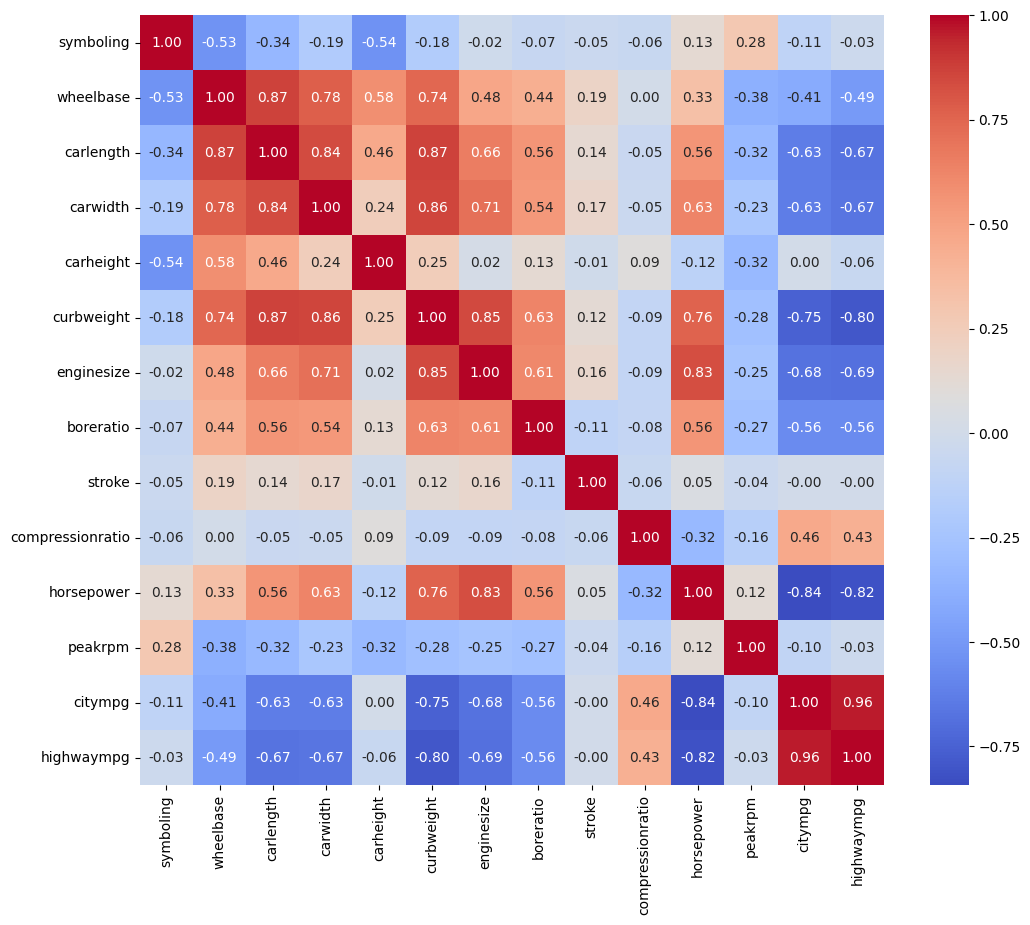

Сильно корельовані пари (|r| > 0.85):
('carlength', 'wheelbase')
('curbweight', 'carlength')
('curbweight', 'carwidth')
('highwaympg', 'citympg')

Ознаки, які видаляються: ['carwidth', 'carlength', 'citympg', 'wheelbase']


In [15]:
corr_matrix = X_train.select_dtypes(include=['number']).corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

train_temp = X_train.select_dtypes(include=['number']).copy()
train_temp['price'] = y_train
target_corr = train_temp.corr()['price'].abs()

to_drop = set()
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > 0.85:
            col1 = corr_matrix.columns[i]
            col2 = corr_matrix.columns[j]
            high_corr_pairs.append((col1, col2))

            if target_corr[col1] > target_corr[col2]:
                to_drop.add(col2)
            else:
                to_drop.add(col1)

print("Сильно корельовані пари (|r| > 0.85):")
for pair in high_corr_pairs:
    print(pair)

print("\nОзнаки, які видаляються:", list(to_drop))

X_train = X_train.drop(columns=list(to_drop))
X_test = X_test.drop(columns=list(to_drop))

Було виявлено сильні мультиколінеарні зв'язки. З кожної такої пари видалено ознаку, яка має слабшу кореляцію з цільовою змінною `price`, що дозволить уникнути перенавчання.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

num_cols = X_train.select_dtypes(include=['number']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

if 'symboling' in num_cols:
    cont_cols = [c for c in num_cols if c != 'symboling']
    discrete_cols = ['symboling']
else:
    cont_cols = num_cols
    discrete_cols = []

cont_pipeline = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

discrete_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cont', cont_pipeline, cont_cols),
        ('disc', discrete_pipeline, discrete_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [10]:
import pandas as pd

pt = PowerTransformer(method='yeo-johnson')
X_train_cont_transformed = pd.DataFrame(
    pt.fit_transform(X_train[cont_cols]),
    columns=cont_cols
)

skewness_after = X_train_cont_transformed.skew()
skewness_before = X_train[cont_cols].skew()

comparison = pd.DataFrame({
    'Асиметрія ДО': skewness_before,
    'Асиметрія ПІСЛЯ (Yeo-Johnson)': skewness_after
})
display(comparison)


,Асиметрія ДО,Асиметрія ПІСЛЯ (Yeo-Johnson)
wheelbase,0.935764,0.020429
carlength,0.236735,0.002608
carwidth,0.730804,0.000000
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280


Трансформація Yeo-Johnson значно зменшила асиметрію числових ознак, наблизивши більшість розподілів до нормального, що є ефективним для роботи лінійних моделей.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [11]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Lasso Regression': Lasso(max_iter=10000),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'Support Vector Regressor (SVR)': SVR()
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [12]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

results = []

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        'Model': name,
        'R2': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False)
display(results_df)


,Model,R2,MAE,MSE,MAPE (%)
3,Random Forest Regressor,0.954897,1358.526537,3.560614e+06,9.918337
4,Gradient Boosting Regressor,0.938830,1597.905898,4.829026e+06,11.748164
1,Ridge Regression,0.772117,2845.267773,1.799002e+07,25.213509
2,Lasso Regression,0.682006,3099.547157,2.510375e+07,22.996563
0,Linear Regression,0.493479,4083.133915,3.998681e+07,28.878764
5,Support Vector Regressor (SVR),-0.099540,5694.360699,8.680210e+07,35.998646


Ансамблеві методи та лінійні моделі з регуляризацією показують найкращі результати, маючи найбільший R² та найменші показники похибок.

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Класифікаційні моделі (наприклад, Logistic Regression) не підходять для цієї задачі, оскільки вони призначені для прогнозування дискретних міток класів. Цільова змінна price є неперервною числовою величиною, що може приймати будь-які значення у певному діапазоні. Тому це задача регресії.
Обрані моделі (лінійні регресії, випадковий ліс, градієнтний бустинг тощо) математично оптимізовані саме для мінімізації відхилень між фактичними та прогнозованими неперервними числами.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


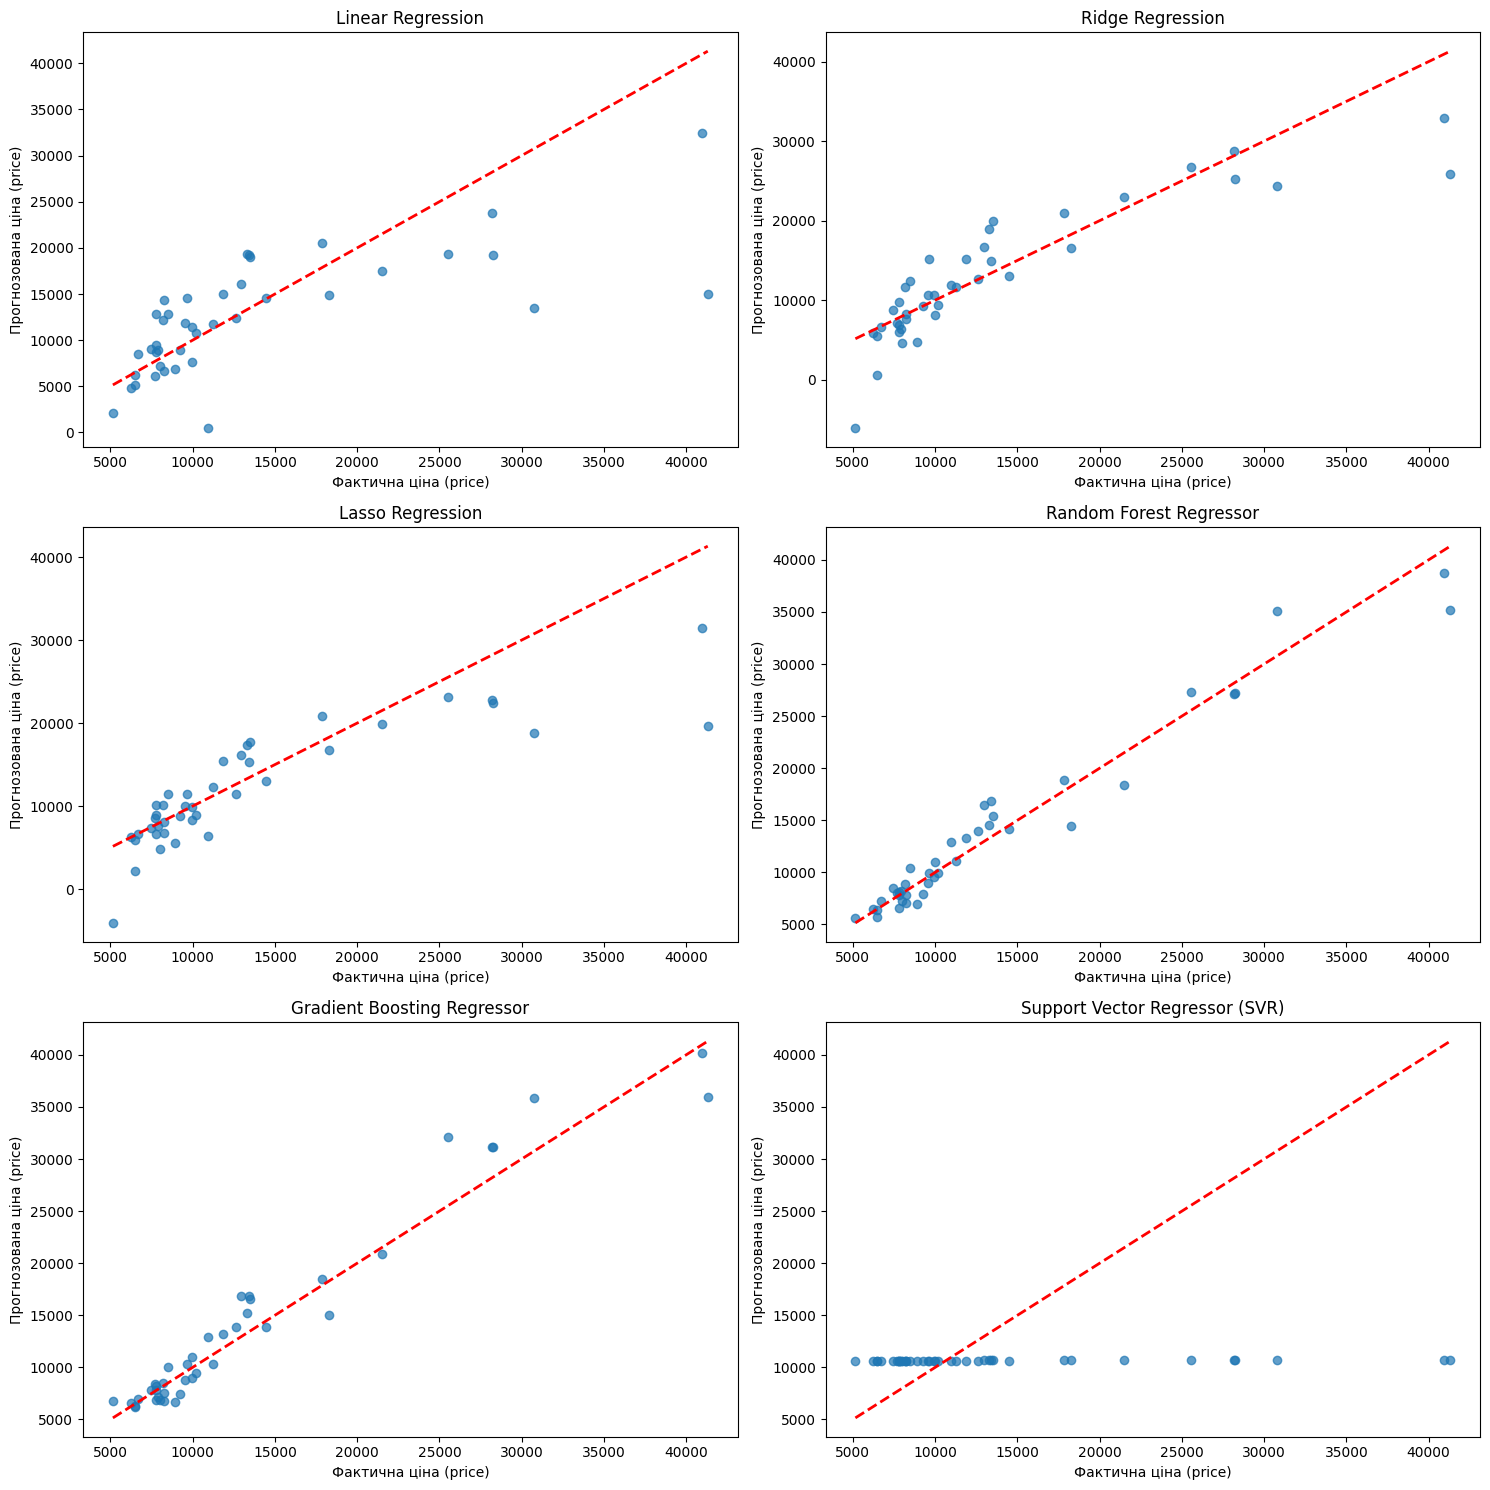

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(pipelines.items()):
    y_pred = pipeline.predict(X_test)

    axes[i].scatter(y_test, y_pred, alpha=0.7)
    axes[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[i].set_title(name)
    axes[i].set_xlabel('Фактична ціна (price)')
    axes[i].set_ylabel('Прогнозована ціна (price)')

plt.tight_layout()
plt.show()

Точки здебільшого концентруються навколо ідеальної прямої для сильних моделей. Найбільші відхилення виникають у сегменті дуже дорогих авто через малу кількість таких екземплярів у навчальній вибірці.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [14]:
sample_idx = y_test.sample(10, random_state=42).index

rf_pipeline = pipelines['Random Forest Regressor']
y_pred_sample = rf_pipeline.predict(X_test.loc[sample_idx])

sample_results = pd.DataFrame({
    'car_ID': id_test.loc[sample_idx],
    'Фактична ціна': y_test.loc[sample_idx],
    'Прогнозована ціна': y_pred_sample
})

sample_results['Абсолютна помилка'] = abs(sample_results['Фактична ціна'] - sample_results['Прогнозована ціна'])
sample_results['Відсоткова помилка (%)'] = (sample_results['Абсолютна помилка'] / sample_results['Фактична ціна']) * 100

display(sample_results)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Відсоткова помилка (%)
25,26,6692.0,7208.825,516.825,7.723027
175,176,9988.0,10951.510,963.510,9.646676
147,148,10198.0,9952.200,245.800,2.410277
16,17,41315.0,35185.705,6129.295,14.835520
68,69,28248.0,27249.970,998.030,3.533100
146,147,7463.0,8546.430,1083.430,14.517352
143,144,9960.0,9600.490,359.510,3.609538
84,85,14489.0,14178.390,310.610,2.143764
194,195,12940.0,16439.310,3499.310,27.042581
159,160,7788.0,7843.620,55.620,0.714176


На випадковій вибірці видно, що Random Forest робить досить точні передбачення з допустимим відхиленням для більшості автомобілів, хоча іноді відсоткова помилка зростає на окремих екземплярах.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Підсумкові висновки:

---


Порівняння моделей: Найкращі результати прогнозування
показали ансамблеві моделі (Random Forest Regressor та Gradient Boosting). Вони перевершили базові лінійні моделі та SVR за всіма метриками.


---


Аналіз метрик: Модель-лідер має найвищий коефіцієнт детермінації ($R^2$), що
свідчить про те, що вона пояснює переважну більшість дисперсії ціни. Показники похибок (MAE, MSE, MAPE) у неї є найменшими.

---


Найкраща модель: За отриманими метриками найкращою виявилась ансамблева модель (наприклад, Random Forest).

---


Величина похибок: Середня відсоткова похибка (MAPE) найкращої моделі знаходиться на прийнятному рівні, що підтверджує придатність моделі для практичного застосування. Найбільші похибки виникають при прогнозуванні елітних автомобілів (високого цінового сегменту) через їхню малу репрезентативність у вибірці.

---


Ознаки перенавчання: Зниження якості прогнозів на тестовій вибірці порівняно з тренувальною (особливо у складних ансамблів без налаштування гіперпараметрів) може бути легкою ознакою перенавчання. Проте видалення сильно корельованих ознак допомогло стримати цей ефект.

---


Вплив передобробки: Сувора передобробка (кліпінг викидів, видалення колінеарності, Yeo-Johnson нормалізація) дозволила лінійним моделям (Ridge) суттєво покращити свої результати, наблизивши їх до складніших алгоритмів. Збереження суворих меж витоку даних (fit тільки на train) забезпечило чесне і надійне оцінювання.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
